# E-commerce Customer Segmentation: RFM + Cohort Retention Analysis

**Business question:** Who are our customers, which ones are most valuable, and do they come back after their first order?

**Data:** [Olist Brazilian E-commerce public dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): about 100K real orders from 2016–2018.

**Approach**
1. Load raw CSVs into SQLite and use **SQL** to build a clean, customer-level table
2. Compute **RFM** (Recency, Frequency, Monetary) and score every customer
3. Group customers into **actionable segments**
4. Build a **monthly cohort retention** table and heatmap
5. Turn the numbers into **business recommendations**

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Colours (one consistent palette for all charts)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b8b7b1"
TEXT, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
})
DATA, IMG, OUT = "../data/", "../images/", "../outputs/"

## 1. Load data into SQLite

We only need three tables:
- `orders`: one row per order (status, purchase date)
- `customers`: maps each order's `customer_id` to the real person, `customer_unique_id`
- `payments`: how much was paid for each order

In [2]:
orders    = pd.read_csv(DATA + "olist_orders_dataset.csv")
customers = pd.read_csv(DATA + "olist_customers_dataset.csv")
payments  = pd.read_csv(DATA + "olist_order_payments_dataset.csv")

for name, df in [("orders", orders), ("customers", customers), ("payments", payments)]:
    print(f"{name:10s} {df.shape[0]:>7,} rows  {df.shape[1]} cols")

conn = sqlite3.connect(":memory:")          # in-memory SQL database
orders.to_sql("orders", conn, index=False)
customers.to_sql("customers", conn, index=False)
payments.to_sql("payments", conn, index=False)

# indexes on the join keys, otherwise SQLite scans the whole table for every row
_ = conn.executescript("""
CREATE INDEX idx_orders_customer   ON orders(customer_id);
CREATE INDEX idx_customers_id      ON customers(customer_id);
CREATE INDEX idx_payments_order    ON payments(order_id);
""")

orders      99,441 rows  8 cols
customers   99,441 rows  5 cols
payments   103,886 rows  5 cols


## 2. Data understanding and cleaning

Two checks before any analysis:
1. **Order status:** only `delivered` orders count as real purchases. Cancelled or unavailable orders are not revenue.
2. **Customer ID trap:** in Olist, `customer_id` is created **fresh for every order**. The real person is `customer_unique_id`. If we used `customer_id`, *every* customer would look like a one-time buyer.

In [3]:
print(orders["order_status"].value_counts(), "\n")
print("Unique customer_id       :", f"{customers['customer_id'].nunique():,}")
print("Unique customer_unique_id:", f"{customers['customer_unique_id'].nunique():,}")

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Unique customer_id       : 99,441
Unique customer_unique_id: 96,096


In [4]:
# Orders per month: the first and last few months are almost empty (data collection
# started/stopped), so we keep Jan-2017 to Aug-2018 only.
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
monthly = orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size()
print(monthly.to_string())

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


### Clean table with SQL
One row per delivered order, with the real customer id and the total order value. Payments are summed per order because one order can be paid in parts, for example with a voucher plus a card.

In [5]:
conn.executescript("""
-- Step 1: One row per DELIVERED order with the REAL customer id and order value
CREATE TABLE delivered_orders AS
SELECT
    o.order_id,
    c.customer_unique_id,                         -- real person (customer_id changes every order!)
    DATE(o.order_purchase_timestamp)  AS order_date,
    p.order_value
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN (
    SELECT order_id, SUM(payment_value) AS order_value   -- an order can have several payments
    FROM payments
    GROUP BY order_id
) p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01';

CREATE INDEX idx_delivered_customer ON delivered_orders(customer_unique_id);
""")
delivered = pd.read_sql("SELECT * FROM delivered_orders", conn, parse_dates=["order_date"])
print(f"Delivered orders analysed: {len(delivered):,}")
print(f"Unique customers         : {delivered['customer_unique_id'].nunique():,}")
print(f"Total revenue (BRL)      : {delivered['order_value'].sum():,.0f}")
delivered.head()

Delivered orders analysed: 96,211
Unique customers         : 93,104
Total revenue (BRL)      : 15,375,875


,order_id,customer_unique_id,order_date,order_value
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,2017-10-02,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,2018-07-24,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,7c142cf63193a1473d2e66489a9ae977,2017-11-18,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13,28.62


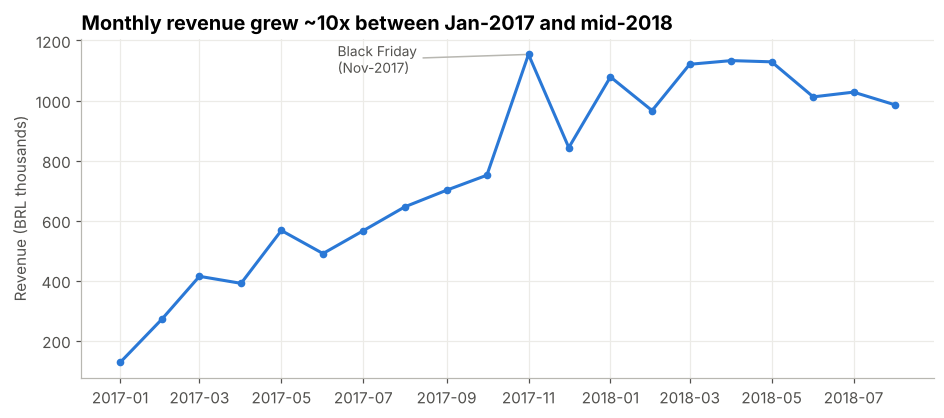

In [6]:
# Business context: revenue & orders over time
m = delivered.set_index("order_date").resample("MS").agg(orders=("order_id", "count"),
                                                        revenue=("order_value", "sum"))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(m.index, m["revenue"] / 1e3, color=BLUE, lw=2, marker="o", ms=4)
ax.set_title("Monthly revenue grew ~10x between Jan-2017 and mid-2018")
ax.set_ylabel("Revenue (BRL thousands)")
ax.annotate("Black Friday\n(Nov-2017)", xy=(pd.Timestamp("2017-11-01"), m.loc["2017-11-01", "revenue"] / 1e3),
            xytext=(-125, -12), textcoords="offset points", color=MUTED, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GREY))
plt.savefig(IMG + "01_monthly_revenue.png"); plt.show()

## 3. RFM metrics (SQL)

| Metric | Question | Calculation |
|---|---|---|
| **Recency** | How recently did they buy? | Days between the last order and 2018-09-01 |
| **Frequency** | How often do they buy? | Number of distinct orders |
| **Monetary** | How much did they spend? | Total order value (BRL) |

`NTILE(5)` splits customers into 5 equal groups, giving each a score from 1 (worst) to 5 (best). For Recency, **fewer days is better**, so it is sorted in descending order.

In [7]:
rfm = pd.read_sql("""
-- Step 2: Recency, Frequency, Monetary per customer + R and M scores (1-5)
-- Reference date = 2018-09-01 (the day after our data ends)
WITH rfm AS (
    SELECT
        customer_unique_id,
        CAST(JULIANDAY('2018-09-01') - JULIANDAY(MAX(order_date)) AS INTEGER) AS recency_days,
        COUNT(DISTINCT order_id)                                            AS frequency,
        ROUND(SUM(order_value), 2)                                          AS monetary
    FROM delivered_orders
    GROUP BY customer_unique_id
)
SELECT
    *,
    NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,  -- most recent buyers get 5
    NTILE(5) OVER (ORDER BY monetary ASC)      AS m_score   -- biggest spenders get 5
FROM rfm;
""", conn)
rfm.describe()

,recency_days,frequency,monetary,r_score,m_score
count,"93,104.00","93,104.00","93,104.00","93,104.00","93,104.00"
mean,239.24,1.03,165.15,3.00,3.00
std,150.95,0.21,226.38,1.41,1.41
min,3.00,1.00,9.59,1.00,1.00
25%,117.00,1.00,63.04,2.00,2.00
50%,221.00,1.00,107.78,3.00,3.00
75%,348.00,1.00,182.50,4.00,4.00
max,604.00,15.00,"13,664.08",5.00,5.00


### Problem with Frequency: most customers buy only once

In [8]:
print(pd.read_sql("""
-- Business question: how many customers ever came back for a 2nd order?
SELECT
    COUNT(*)                                              AS total_customers,
    SUM(CASE WHEN n_orders > 1 THEN 1 ELSE 0 END)         AS repeat_customers,
    ROUND(100.0 * SUM(CASE WHEN n_orders > 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS repeat_rate_pct
FROM (
    SELECT customer_unique_id, COUNT(DISTINCT order_id) AS n_orders
    FROM delivered_orders
    GROUP BY customer_unique_id
);
""", conn).T)
print()
print(rfm["frequency"].value_counts().sort_index().to_string())

                         0
total_customers  93,104.00
repeat_customers  2,789.00
repeat_rate_pct       3.00

frequency
1     90315
2      2562
3       180
4        28
5         9
6         5
7         3
9         1
15        1


About **97% of customers bought exactly once**. If we run `NTILE(5)` on Frequency, people with *identical* behaviour (1 order) would get scores of 1, 2, 3 and 4 just because of tie order. That is meaningless.

**Fix:** score Frequency with **business rules** instead of quintiles:
`1 order → F=1`, `2 orders → F=2`, `3+ orders → F=3`.

This is a common real-world adjustment. Textbook RFM assumes frequent buyers, which isn't true for marketplaces selling furniture, electronics and similar durable goods.

In [9]:
rfm["f_score"] = np.select([rfm["frequency"] >= 3, rfm["frequency"] == 2], [3, 2], default=1)

# Sanity check: recency and monetary scores should increase with the raw values
print(rfm.groupby("r_score")["recency_days"].agg(["min", "max"]))
print(rfm.groupby("m_score")["monetary"].agg(["min", "max"]))

         min  max
r_score          
1        383  604
2        270  383
3        179  270
4         94  179
5          3   94
           min       max
m_score                 
1         9.59     55.24
2        55.24     87.36
3        87.36    132.66
4       132.68    208.48
5       208.51 13,664.08


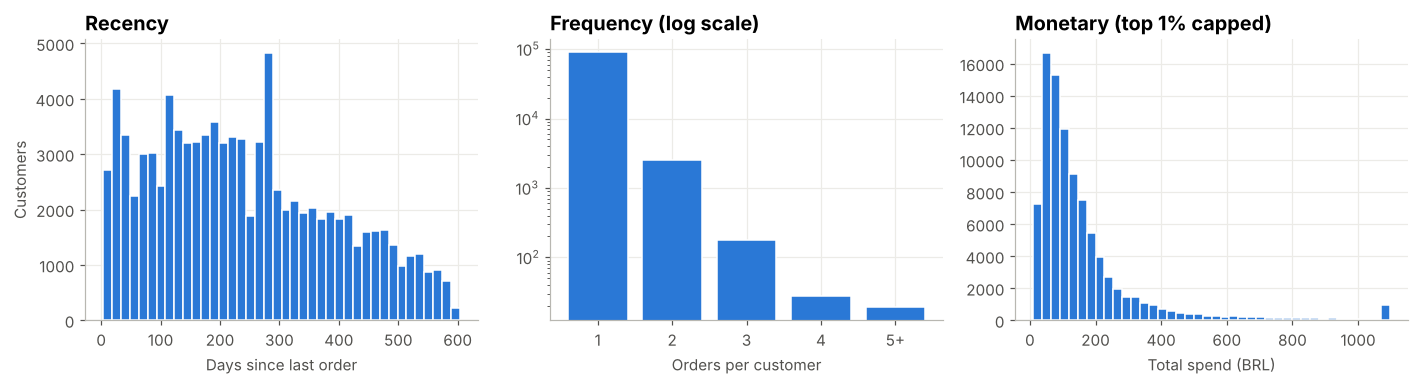

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(rfm["recency_days"], bins=40, color=BLUE, edgecolor="white")
axes[0].set_title("Recency"); axes[0].set_xlabel("Days since last order")
f_counts = rfm["frequency"].clip(upper=5).value_counts().sort_index()
axes[1].bar(["1", "2", "3", "4", "5+"], f_counts.values, color=BLUE, edgecolor="white")
axes[1].set_yscale("log"); axes[1].set_title("Frequency (log scale)"); axes[1].set_xlabel("Orders per customer")
axes[2].hist(rfm["monetary"].clip(upper=rfm["monetary"].quantile(0.99)), bins=40, color=BLUE, edgecolor="white")
axes[2].set_title("Monetary (top 1% capped)"); axes[2].set_xlabel("Total spend (BRL)")
axes[0].set_ylabel("Customers")
plt.tight_layout(); plt.savefig(IMG + "02_rfm_distributions.png"); plt.show()

## 4. Customer segments

We use simple, explainable rules. The order matters: a customer gets the **first** rule they match.

| Segment | Rule | Meaning |
|---|---|---|
| Champions | repeat buyer (F≥2) & R≥4 | Bought more than once, and recently |
| Loyal | repeat buyer & R=3 | Repeat buyers, not very recent |
| At Risk | (repeat buyer OR M≥4) & R≤2 | Valuable customers who haven't returned for a long time |
| Promising (High Value) | one order, R≥4, M≥4 | New customers who spent a lot |
| New Customers | one order, R≥4 | Recent first-time buyers |
| Need Attention | one order, R=3 | Middle of the road, slipping away |
| Hibernating | everything else (old, low value, one order) | Low priority |

In [11]:
r, f, mo = rfm["r_score"], rfm["f_score"], rfm["m_score"]
conditions = [
    (f >= 2) & (r >= 4),
    (f >= 2) & (r == 3),
    ((f >= 2) | (mo >= 4)) & (r <= 2),
    (f == 1) & (r >= 4) & (mo >= 4),
    (f == 1) & (r >= 4),
    (f == 1) & (r == 3),
]
labels = ["Champions", "Loyal", "At Risk", "Promising (High Value)", "New Customers", "Need Attention"]
rfm["segment"] = np.select(conditions, labels, default="Hibernating")
SEG_ORDER = labels + ["Hibernating"]

summary = (rfm.groupby("segment")
              .agg(customers=("customer_unique_id", "count"),
                   avg_recency_days=("recency_days", "mean"),
                   avg_orders=("frequency", "mean"),
                   avg_spend=("monetary", "mean"),
                   revenue=("monetary", "sum"))
              .reindex(SEG_ORDER))
summary["pct_customers"] = 100 * summary["customers"] / summary["customers"].sum()
summary["pct_revenue"]   = 100 * summary["revenue"] / summary["revenue"].sum()
summary.round(1)

,customers,avg_recency_days,avg_orders,avg_spend,revenue,pct_customers,pct_revenue
segment,,,,,,,
Champions,1197,91.00,2.20,322.90,"386,549.50",1.30,2.50
Loyal,602,219.00,2.10,301.70,"181,598.80",0.60,1.20
At Risk,14690,393.10,1.10,306.70,"4,505,241.00",15.80,29.30
Promising (High Value),14404,93.80,1.00,302.10,"4,351,201.50",15.50,28.30
New Customers,21640,92.00,1.00,73.00,"1,579,571.80",23.20,10.30
Need Attention,18019,221.80,1.00,151.70,"2,733,627.20",19.40,17.80
Hibernating,22552,395.50,1.00,72.60,"1,638,085.60",24.20,10.70


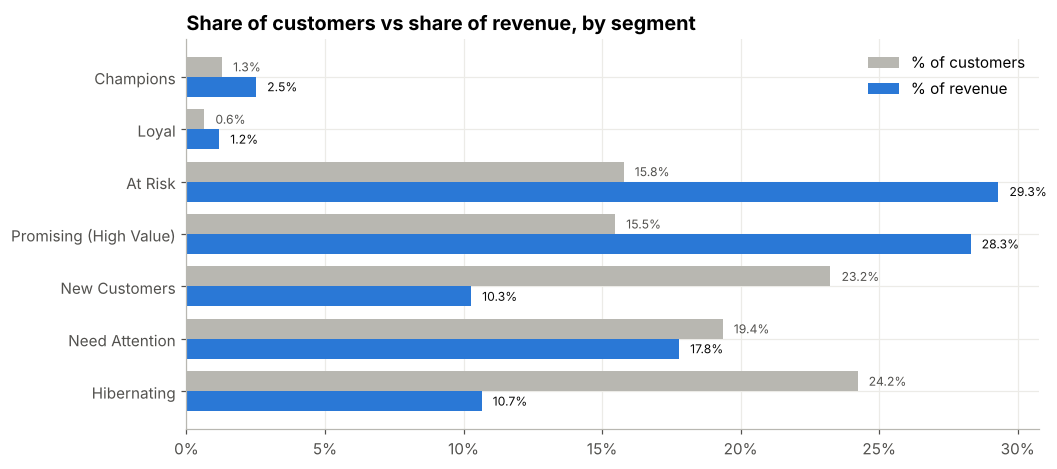

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(SEG_ORDER)); h = 0.38
ax.barh(y - h/2, summary["pct_customers"], height=h, color=GREY, label="% of customers")
ax.barh(y + h/2, summary["pct_revenue"],   height=h, color=BLUE, label="% of revenue")
for i, (c, rv) in enumerate(zip(summary["pct_customers"], summary["pct_revenue"])):
    ax.text(c + 0.4,  i - h/2, f"{c:.1f}%",  va="center", fontsize=8, color=MUTED)
    ax.text(rv + 0.4, i + h/2, f"{rv:.1f}%", va="center", fontsize=8, color=TEXT)
ax.set_yticks(y, SEG_ORDER); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Share of customers vs share of revenue, by segment")
ax.legend(loc="upper right", frameon=False)
plt.savefig(IMG + "03_segments_customers_vs_revenue.png"); plt.show()

### Revenue concentration (Pareto check)
How much revenue comes from the top 20% of customers?

Top 20% of customers generate 53.5% of revenue


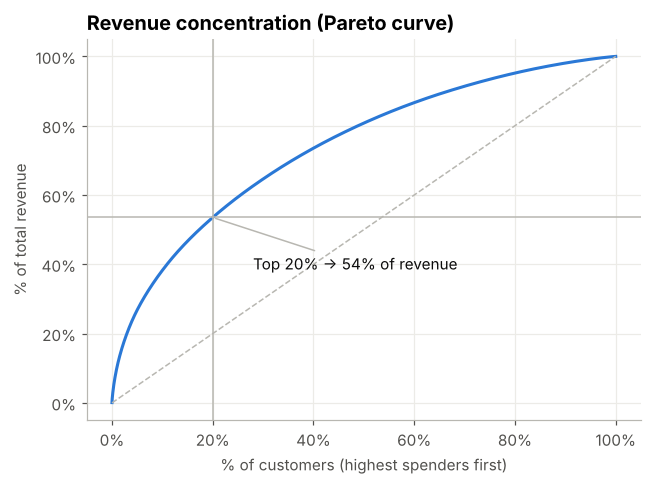

In [13]:
spend = rfm["monetary"].sort_values(ascending=False).reset_index(drop=True)
cum_rev = spend.cumsum() / spend.sum() * 100
cum_cust = (np.arange(1, len(spend) + 1) / len(spend)) * 100
top20_share = cum_rev[int(len(spend) * 0.2) - 1]
print(f"Top 20% of customers generate {top20_share:.1f}% of revenue")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(cum_cust, cum_rev, color=BLUE, lw=2)
ax.plot([0, 100], [0, 100], color=GREY, lw=1, ls="--")
ax.axvline(20, color=GREY, lw=1); ax.axhline(top20_share, color=GREY, lw=1)
ax.annotate(f"Top 20% → {top20_share:.0f}% of revenue", xy=(20, top20_share), xytext=(28, top20_share - 15),
            color=TEXT, fontsize=10, arrowprops=dict(arrowstyle="-", color=GREY))
ax.set_xlabel("% of customers (highest spenders first)"); ax.set_ylabel("% of total revenue")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Revenue concentration (Pareto curve)")
plt.savefig(IMG + "04_pareto_curve.png"); plt.show()

## 5. Cohort retention analysis

A **cohort** is the group of customers who made their **first** purchase in the same month.
For each cohort we check what % of customers ordered again 1, 2, 3 … months later.

In [14]:
cohort_df = pd.read_sql("""
-- Cohort base: each customer's first purchase month + every month they ordered in
WITH first_purchase AS (
    SELECT customer_unique_id, MIN(STRFTIME('%Y-%m', order_date)) AS cohort_month
    FROM delivered_orders
    GROUP BY customer_unique_id
)
SELECT DISTINCT
    f.cohort_month,
    STRFTIME('%Y-%m', d.order_date) AS order_month,
    d.customer_unique_id
FROM delivered_orders d
JOIN first_purchase f ON d.customer_unique_id = f.customer_unique_id;
""", conn)

# months between first purchase and this order
to_period = lambda s: pd.PeriodIndex(s, freq="M")
cohort_df["month_index"] = (to_period(cohort_df["order_month"]) - to_period(cohort_df["cohort_month"])).map(lambda x: x.n)

counts = (cohort_df.groupby(["cohort_month", "month_index"])["customer_unique_id"]
                   .nunique().unstack(fill_value=0))
cohort_size = counts[0]
retention = counts.divide(cohort_size, axis=0) * 100      # % of each cohort still buying
retention.iloc[:, :7].round(2)

month_index,0,1,2,3,4,5,6
cohort_month,,,,,,,
2017-01,100.00,0.28,0.28,0.14,0.42,0.14,0.42
2017-02,100.00,0.18,0.31,0.12,0.43,0.12,0.25
2017-03,100.00,0.44,0.36,0.40,0.36,0.16,0.16
2017-04,100.00,0.62,0.22,0.18,0.27,0.27,0.35
2017-05,100.00,0.46,0.46,0.29,0.29,0.32,0.41
2017-06,100.00,0.49,0.40,0.43,0.30,0.40,0.36
2017-07,100.00,0.53,0.35,0.24,0.29,0.21,0.32
2017-08,100.00,0.69,0.35,0.27,0.35,0.52,0.30
2017-09,100.00,0.70,0.55,0.27,0.45,0.22,0.22


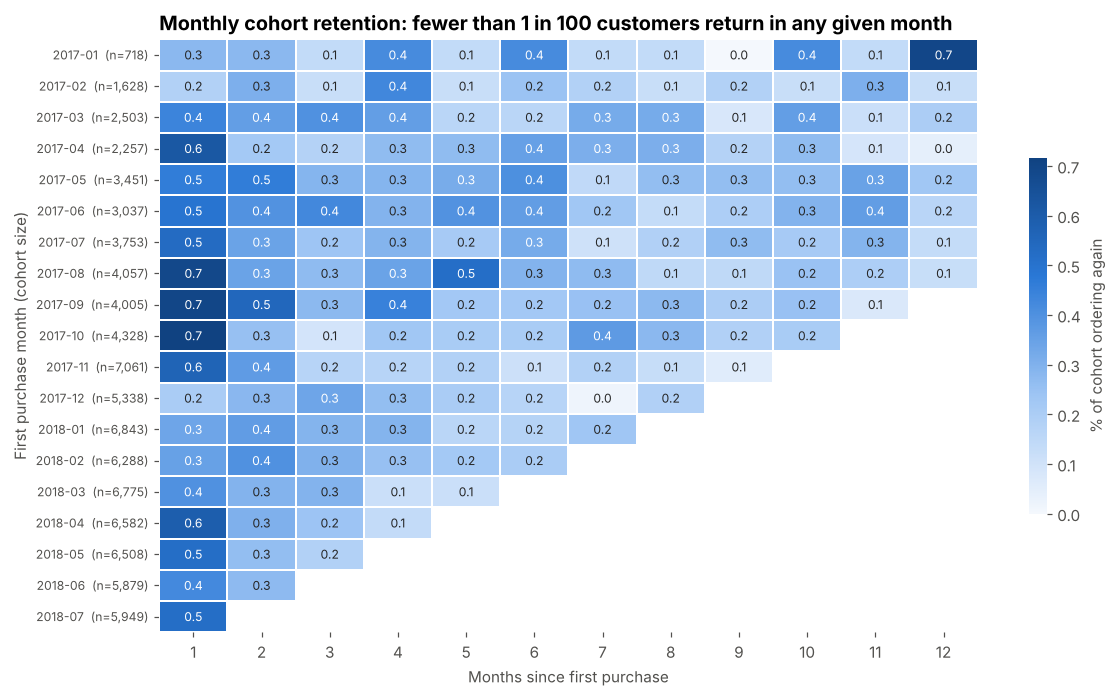

In [15]:
# Heatmap: first 12 months after the first purchase (month 0 is always 100%, so we skip it)
heat = retention.loc[retention.index < "2018-08", 1:12].copy()   # Aug-2018 cohort has no later months
# blank out cells that are in the future (not enough data yet)
last = pd.Period("2018-08", "M")
for cm in heat.index:
    max_idx = (last - pd.Period(cm, "M")).n
    heat.loc[cm, heat.columns > max_idx] = np.nan

blues = sns.blend_palette(["#f4f8fd", "#9ec5f4", "#2a78d6", "#104281"], as_cmap=True)
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(heat, annot=True, fmt=".1f", cmap=blues, vmin=0, vmax=heat.max().max(),
            linewidths=1, linecolor="white", cbar_kws={"label": "% of cohort ordering again", "shrink": 0.6},
            annot_kws={"fontsize": 8}, ax=ax)
ax.set_yticklabels([f"{c}  (n={cohort_size[c]:,})" for c in heat.index], rotation=0, fontsize=8)
ax.set_xlabel("Months since first purchase"); ax.set_ylabel("First purchase month (cohort size)")
ax.set_title("Monthly cohort retention: fewer than 1 in 100 customers return in any given month")
ax.grid(False)
plt.savefig(IMG + "05_cohort_retention_heatmap.png"); plt.show()

In [16]:
# Average retention curve across cohorts + cumulative "ever came back" rate
avg_curve = heat.mean()
ever_returned = (rfm["frequency"] > 1).mean() * 100
print("Average % of a cohort ordering in month N:")
print(avg_curve.round(2).to_string())
print(f"\nOverall: only {ever_returned:.1f}% of customers EVER placed a second order")

Average % of a cohort ordering in month N:
month_index
1    0.48
2    0.34
3    0.25
4    0.29
5    0.23
6    0.26
7    0.21
8    0.21
9    0.16
10   0.26
11   0.21
12   0.21

Overall: only 3.0% of customers EVER placed a second order


## 6. Key insights

The numbers below are printed from the analysis so the text always matches the data.

In [17]:
s = summary
print(f"1. Retention is the core problem: {ever_returned:.1f}% of customers ever placed a 2nd order, "
      f"and monthly cohort retention stays below ~{avg_curve.max():.1f}%.")
print(f"2. Revenue is concentrated: the top 20% of customers bring {top20_share:.0f}% of revenue.")
print(f"3. 'At Risk' customers are {s.loc['At Risk','pct_customers']:.0f}% of the base but "
      f"{s.loc['At Risk','pct_revenue']:.0f}% of revenue (avg spend BRL {s.loc['At Risk','avg_spend']:.0f} "
      f"vs BRL {rfm['monetary'].mean():.0f} overall).")
print(f"4. Repeat buyers (Champions + Loyal) are only {s.loc[['Champions','Loyal'],'pct_customers'].sum():.1f}% of customers, "
      f"but they spend {s.loc['Champions','avg_spend']/rfm['monetary'].mean():.1f}x the average (Champions).")
print(f"5. 'Promising (High Value)' new customers: {s.loc['Promising (High Value)','customers']:,} people. "
      f"Converting them to a 2nd order is the cheapest growth lever.")

1. Retention is the core problem: 3.0% of customers ever placed a 2nd order, and monthly cohort retention stays below ~0.5%.
2. Revenue is concentrated: the top 20% of customers bring 54% of revenue.
3. 'At Risk' customers are 16% of the base but 29% of revenue (avg spend BRL 307 vs BRL 165 overall).
4. Repeat buyers (Champions + Loyal) are only 1.9% of customers, but they spend 2.0x the average (Champions).
5. 'Promising (High Value)' new customers: 14,404 people. Converting them to a 2nd order is the cheapest growth lever.


## 7. Recommendations

| Segment | Action |
|---|---|
| **Champions / Loyal** | VIP perks, early access, referral programme, ask for reviews |
| **At Risk** | Personalised win-back email or offer. High past spend makes this the best ROI target |
| **Promising (High Value)** | Strong post-purchase journey: delivery follow-up, related-product suggestions, discount on 2nd order within 30 days |
| **New Customers** | Onboarding email series, low-value coupon for a 2nd purchase |
| **Need Attention** | Reminder campaigns with category-based recommendations |
| **Hibernating** | Low-cost channels only (generic newsletter); don't spend paid budget |

**Overall:** Olist is an *acquisition-driven* business. Even a small improvement in 2nd-order conversion would compound, because acquiring a new customer costs far more than retaining one.

In [18]:
# Save outputs for anyone who wants to use them (e.g., in Power BI / Excel)
rfm.to_csv(OUT + "customer_rfm_segments.csv", index=False)
summary.round(2).to_csv(OUT + "segment_summary.csv")
retention.round(3).to_csv(OUT + "cohort_retention_table.csv")
print("Saved:", OUT + "customer_rfm_segments.csv", OUT + "segment_summary.csv", OUT + "cohort_retention_table.csv")

Saved: ../outputs/customer_rfm_segments.csv ../outputs/segment_summary.csv ../outputs/cohort_retention_table.csv


## 8. Limitations and next steps
- Monetary uses payment value, which includes freight. Product-only revenue would be slightly lower.
- The dataset ends in Aug-2018, so recent cohorts have fewer months of history.
- **Next:** add product category and state to each segment, build a Power BI dashboard on top of `outputs/`, and predict 2nd-purchase probability with a classification model.